# NN_L8_gan_acf

**Lecture 8 of Neural Networks and Deep Learning (NN). Autocorrelation of absolute daily returns, S&P 500 2005-2019 against GAN samples: the GAN draws days independently.**

Neural Networks and Deep Learning (NN), Lecture 8 · Daniel Traian Pele, Bucharest University of Economic Studies

[Open in Colab](https://colab.research.google.com/github/danpele/NEURAL_BIZ/blob/main/Quantlets/L8/NN_L8_gan_acf/NN_L8_gan_acf.ipynb)

In [1]:
import os
# course data: the local copy of the repository if there is one, else the public repository on GitHub
_LOCAL = os.path.join('..', '..', '..', 'data', 'clean')
DATA = _LOCAL + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/NEURAL_BIZ/main/data/clean/'
REPO = os.path.join('..', '..', '..') + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/NEURAL_BIZ/main/'

In [2]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings('ignore')
# course chart style: transparent background, no gridlines, legend at the bottom outside the axes, four-digit years
plt.rcParams.update({
    'figure.facecolor': 'none', 'axes.facecolor': 'none', 'savefig.transparent': True,
    'axes.grid': False, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.edgecolor': '#222222', 'axes.labelcolor': '#222222', 'xtick.color': '#222222', 'ytick.color': '#222222',
    'text.color': '#222222', 'font.size': 11, 'axes.labelsize': 11, 'legend.fontsize': 10.5, 'legend.frameon': False,
    'lines.linewidth': 1.4, 'font.family': 'DejaVu Sans'})
SERIES = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300', '#6250d6', '#e34948']
PAL = {'data': '#2a78d6', 'model': '#eb6834', 'benchmark': '#1baf7a', 'alt': '#eda100',
       'train': '#2a78d6', 'valid': '#eb6834', 'test': '#6250d6', 'positive': '#e34948', 'negative': '#2a78d6'}


def legend_bottom(fig, ncol=4):
    h, l_ = [], []
    for ax in fig.axes:
        for hh, ll in zip(*ax.get_legend_handles_labels()):
            if ll not in l_:
                h.append(hh); l_.append(ll)
    if h:
        fig.legend(h, l_, loc='lower center', ncol=min(ncol, len(h)), bbox_to_anchor=(0.5, 0.0), frameon=False)


def show(key, label, value):
    # print a number of the slide; [key] = its name in lectures/Lk/Lk_numbers.json
    print(f'{label} = {value}   [{key}]')

$\rho_\ell(|r|)$ for lags 1-20.

ACF of |r| at lag 1, real = 0.28   [gan.acf1_real]
ACF of |r| at lag 20, real = 0.27   [gan.acf20_real]
ACF of |r| at lag 1, GAN = -0.01   [gan.acf1_gan]


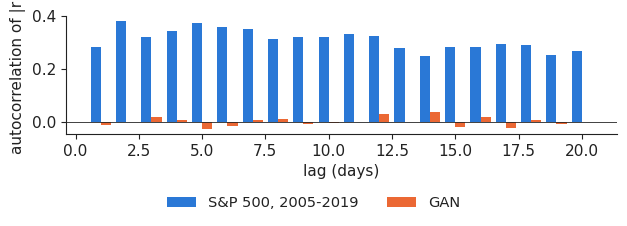

In [3]:
x = pd.read_csv(DATA + 'markets_daily.csv', parse_dates=['date'])
px = x[x.ticker == 'SP500'].set_index('date')['adjclose'].dropna()
end = (px.index.max() + pd.Timedelta(days=1)).to_period('M').to_timestamp() - pd.Timedelta(days=1)
r = np.log(px.loc[:end]).diff().dropna()
rtr = r.loc[:'2019-12-31']
s_tr = float(rtr.std())
ztr = rtr.values / s_tr
def acf_abs(x, lags=20):
    a = np.abs(x) - np.abs(x).mean()
    return np.array([np.sum(a[l:] * a[:-l]) / np.sum(a * a) for l in range(1, lags + 1)])
ar = acf_abs(ztr)
ag = pd.read_csv(REPO + 'lectures/L8/results/' + 'gan_acf.csv').gan.values
show('gan.acf1_real', 'ACF of |r| at lag 1, real', round(float(ar[0]), 2))
show('gan.acf20_real', 'ACF of |r| at lag 20, real', round(float(ar[-1]), 2))
show('gan.acf1_gan', 'ACF of |r| at lag 1, GAN', round(float(ag[0]), 2))
lags = np.arange(1, 21)
fig, ax = plt.subplots(figsize=(6.4, 2.3))
ax.bar(lags - 0.2, ar, 0.4, color=PAL['data'], label='S&P 500, 2005-2019')
ax.bar(lags + 0.2, ag, 0.4, color=PAL['model'], label='GAN')
ax.axhline(0, color='#222222', lw=0.6)
ax.set_xlabel('lag (days)'); ax.set_ylabel('autocorrelation of |r|')
legend_bottom(fig)
fig.tight_layout(rect=(0, 0.12, 1, 1))
fig.savefig('gan_acf.png', dpi=200, transparent=True, bbox_inches='tight')
plt.show()